# DSAI5 – Evaluation 1: k-Nearest-Neighbors auf dem Wine-Datensatz


Alle Ergebnisse werden in der Form `Accuracy = 0.9xx ± 0.0xx (5-fold CV)` angegeben (Mittelwert ± Standardabweichung über die 5 Folds).

## Setup

In [1]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from sklearn.datasets import load_wine
from sklearn.metrics import accuracy_score
from sklearn.model_selection import (StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_score, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True, as_frame=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
K_VALUES = [1, 3, 5, 9, 15, 25]

print(X.shape, y.shape)
print(y.value_counts().sort_index())

(178, 13) (178,)
target
0    59
1    71
2    48
Name: count, dtype: int64


# Teil A

## A1: Pipeline StandardScaler → KNeighborsClassifier

In [2]:
pipeline = make_pipeline(StandardScaler(), KNeighborsClassifier())
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the 

## A2: StratifiedKFold für k ∈ {1, 3, 5, 9, 15, 25}

In [3]:
rows = []
for k in K_VALUES:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    result = cross_validate(model, X, y, cv=cv, return_train_score=True)
    train, val = result["train_score"], result["test_score"]
    rows.append({"k": k, "train_mean": train.mean(), "train_sd": train.std(),
                 "val_mean": val.mean(), "val_sd": val.std()})
    print(f"k={k:>2}  Train: Accuracy = {train.mean():.3f} ± {train.std():.3f} (5-fold CV)   "
          f"Validation: Accuracy = {val.mean():.3f} ± {val.std():.3f} (5-fold CV)")

results_scaled = pd.DataFrame(rows)

k= 1  Train: Accuracy = 1.000 ± 0.000 (5-fold CV)   Validation: Accuracy = 0.955 ± 0.022 (5-fold CV)
k= 3  Train: Accuracy = 0.968 ± 0.008 (5-fold CV)   Validation: Accuracy = 0.966 ± 0.021 (5-fold CV)
k= 5  Train: Accuracy = 0.976 ± 0.007 (5-fold CV)   Validation: Accuracy = 0.972 ± 0.018 (5-fold CV)
k= 9  Train: Accuracy = 0.973 ± 0.008 (5-fold CV)   Validation: Accuracy = 0.972 ± 0.025 (5-fold CV)


k=15  Train: Accuracy = 0.979 ± 0.006 (5-fold CV)   Validation: Accuracy = 0.978 ± 0.021 (5-fold CV)


k=25  Train: Accuracy = 0.973 ± 0.005 (5-fold CV)   Validation: Accuracy = 0.966 ± 0.021 (5-fold CV)


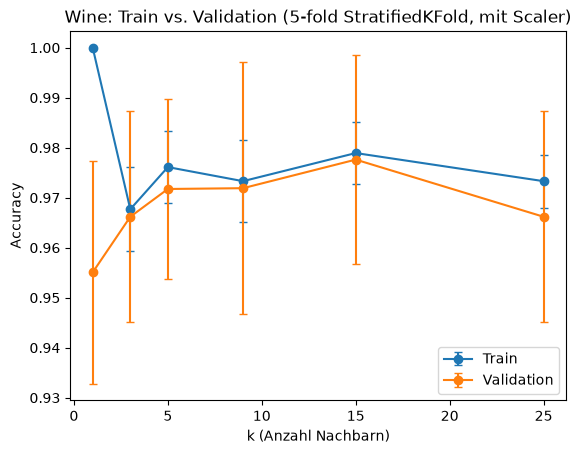

In [4]:
plt.errorbar(results_scaled["k"], results_scaled["train_mean"], yerr=results_scaled["train_sd"], marker="o", capsize=3, label="Train")
plt.errorbar(results_scaled["k"], results_scaled["val_mean"], yerr=results_scaled["val_sd"], marker="o", capsize=3, label="Validation")
plt.xlabel("k (Anzahl Nachbarn)")
plt.ylabel("Accuracy")
plt.title("Wine: Train vs. Validation (5-fold StratifiedKFold, mit Scaler)")
plt.legend()
plt.show()

## A3: Wahl von k

In [5]:
chosen_k = 15
chosen = results_scaled.set_index("k").loc[chosen_k]
print(f"Gewählt: k = {chosen_k}")
print(f"Train:      Accuracy = {chosen.train_mean:.3f} ± {chosen.train_sd:.3f} (5-fold CV)")
print(f"Validation: Accuracy = {chosen.val_mean:.3f} ± {chosen.val_sd:.3f} (5-fold CV)")

Gewählt: k = 15
Train:      Accuracy = 0.979 ± 0.006 (5-fold CV)
Validation: Accuracy = 0.978 ± 0.021 (5-fold CV)


**Begründung:** Ich wähle **k = 15**, weil Train- und Validation-Accuracy dort fast gleich sind (0.979 vs. 0.978) – das Modell überanpasst also nicht wie bei k = 1 (Train 1.000, Validation nur 0.955), ist aber auch noch nicht so grob, dass es wie bei k = 25 wieder schlechter wird (Underfitting).
Da die Unterschiede zwischen k = 5, 9 und 15 kleiner als eine Standardabweichung (≈ 0.02) sind, ist k = 15 kein „klarer Sieger“, sondern ein robuster Wert aus dem stabilen Bereich, der durch das Mitteln über 15 Nachbarn weniger empfindlich auf einzelne Ausreißer reagiert.

## A4: Was passiert ohne StandardScaler?

In [6]:
X.describe().round(3)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000
mean,13.001,2.336,2.367,19.495,99.742,2.295,2.029,0.362,1.591,5.058,0.957,2.612,746.893
std,0.812,1.117,0.274,3.340,14.282,0.626,0.999,0.124,0.572,2.318,0.229,0.710,314.907
min,11.030,0.740,1.360,10.600,70.000,0.980,0.340,0.130,0.410,1.280,0.480,1.270,278.000
25%,12.362,1.602,2.210,17.200,88.000,1.742,1.205,0.270,1.250,3.220,0.782,1.938,500.500
50%,13.050,1.865,2.360,19.500,98.000,2.355,2.135,0.340,1.555,4.690,0.965,2.780,673.500
75%,13.678,3.082,2.558,21.500,107.000,2.800,2.875,0.438,1.950,6.200,1.120,3.170,985.000
max,14.830,5.800,3.230,30.000,162.000,3.880,5.080,0.660,3.580,13.000,1.710,4.000,1680.000


In [7]:
X[["proline", "hue"]].describe().round(3)

,proline,hue
count,178.000,178.000
mean,746.893,0.957
std,314.907,0.229
min,278.000,0.480
25%,500.500,0.782
50%,673.500,0.965
75%,985.000,1.120
max,1680.000,1.710


In [8]:
rows = []
for k in K_VALUES:
    model = KNeighborsClassifier(n_neighbors=k)  # ohne StandardScaler
    result = cross_validate(model, X, y, cv=cv, return_train_score=True)
    train, val = result["train_score"], result["test_score"]
    rows.append({"k": k, "train_mean": train.mean(), "train_sd": train.std(),
                 "val_mean": val.mean(), "val_sd": val.std()})
    print(f"k={k:>2}  Train: Accuracy = {train.mean():.3f} ± {train.std():.3f} (5-fold CV)   "
          f"Validation: Accuracy = {val.mean():.3f} ± {val.std():.3f} (5-fold CV)")

results_unscaled = pd.DataFrame(rows)

k= 1  Train: Accuracy = 1.000 ± 0.000 (5-fold CV)   Validation: Accuracy = 0.719 ± 0.061 (5-fold CV)
k= 3  Train: Accuracy = 0.868 ± 0.016 (5-fold CV)   Validation: Accuracy = 0.679 ± 0.052 (5-fold CV)


k= 5  Train: Accuracy = 0.791 ± 0.022 (5-fold CV)   Validation: Accuracy = 0.680 ± 0.043 (5-fold CV)
k= 9  Train: Accuracy = 0.767 ± 0.019 (5-fold CV)   Validation: Accuracy = 0.686 ± 0.025 (5-fold CV)
k=15  Train: Accuracy = 0.743 ± 0.015 (5-fold CV)   Validation: Accuracy = 0.703 ± 0.025 (5-fold CV)


k=25  Train: Accuracy = 0.736 ± 0.015 (5-fold CV)   Validation: Accuracy = 0.652 ± 0.041 (5-fold CV)


In [9]:
comparison = pd.DataFrame({
    "k": K_VALUES,
    "Validation mit Scaler": results_scaled["val_mean"].round(3),
    "Validation ohne Scaler": results_unscaled["val_mean"].round(3),
})
comparison

,k,Validation mit Scaler,Validation ohne Scaler
0,1,0.955,0.719
1,3,0.966,0.679
2,5,0.972,0.680
3,9,0.972,0.686
4,15,0.978,0.703
5,25,0.966,0.652


 Ohne StandardScaler fällt die Validation-Accuracy von ca. 0.97 auf ca. 0.65–0.72.
kNN entscheidet über den **euklidischen Abstand**, und dabei zählt jedes Feature mit seiner Größenordnung: `proline` liegt zwischen 278 und 1680 (Standardabweichung ≈ 315), `hue` nur zwischen 0.48 und 1.71 (Standardabweichung ≈ 0.23) – ein Unterschied von über drei Zehnerpotenzen.
Dadurch besteht der Abstand fast nur aus `proline` (und `magnesium`), während `hue` und die anderen kleinen Features praktisch ignoriert werden, obwohl sie für die Klassen sehr informativ sind.
Der StandardScaler bringt alle Features auf Mittelwert 0 und Standardabweichung 1, sodass jedes Feature gleich viel zum Abstand beiträgt.
Weil der Scaler in der Pipeline steckt, wird er in jedem Fold nur auf den Trainingsdaten gefittet – so gelangt keine Information aus dem Validation-Fold ins Training.

## A5: GridSearchCV über k und weights

In [10]:
grid = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    param_grid={
        "kneighborsclassifier__n_neighbors": K_VALUES,
        "kneighborsclassifier__weights": ["uniform", "distance"],
    },
    cv=cv, scoring="accuracy", return_train_score=True,
)
grid.fit(X, y)

best_index = grid.best_index_
print("Beste Parameter:", grid.best_params_)
print(f"Validation: Accuracy = {grid.best_score_:.3f} ± {grid.cv_results_['std_test_score'][best_index]:.3f} (5-fold CV)")

Beste Parameter: {'kneighborsclassifier__n_neighbors': 15, 'kneighborsclassifier__weights': 'uniform'}
Validation: Accuracy = 0.978 ± 0.021 (5-fold CV)


In [11]:
grid_table = pd.DataFrame(grid.cv_results_)[[
    "param_kneighborsclassifier__n_neighbors", "param_kneighborsclassifier__weights",
    "mean_train_score", "mean_test_score", "std_test_score", "rank_test_score",
]]
grid_table.columns = ["k", "weights", "train", "validation", "sd", "rank"]
grid_table.sort_values("rank").round(3)

,k,weights,train,validation,sd,rank
9,15,distance,1.000,0.978,0.021,1
8,15,uniform,0.979,0.978,0.021,1
6,9,uniform,0.973,0.972,0.025,3
7,9,distance,1.000,0.972,0.025,3
11,25,distance,1.000,0.972,0.025,3
4,5,uniform,0.976,0.972,0.018,6
5,5,distance,1.000,0.972,0.018,6
2,3,uniform,0.968,0.966,0.021,8
3,3,distance,1.000,0.966,0.021,8
10,25,uniform,0.973,0.966,0.021,8


**Kommentar:** GridSearchCV liefert ebenfalls **k = 15** – das ist kein Zufall, weil es dasselbe `StratifiedKFold`-Objekt und damit exakt dieselben Folds verwendet wie meine Schleife; die Validation-Werte sind identisch.
Der Unterschied liegt bei `weights`: `uniform` und `distance` erzielen für jedes k dieselbe Validation-Accuracy, bei Gleichstand nimmt GridSearchCV einfach die zuerst gelistete Kombination (`uniform`). `distance` erreicht allerdings immer 1.000 Train-Accuracy (jeder Trainingspunkt ist sein eigener Nachbar mit Abstand 0), was auf mehr Overfitting hindeutet.
Außerdem wählt GridSearchCV stur den höchsten Mittelwert; da die Top-Kandidaten innerhalb einer Standardabweichung liegen, könnte mit einem anderen `random_state` auch k = 5 oder 9 gewinnen – die Begründung aus A3 bleibt deshalb wichtig.

## A6 (Bonus): Absichtliches Leakage-Feature

In [12]:
rng = np.random.default_rng(0)
X_leak = X.copy()
# Leakage: Feature wird direkt aus dem Label berechnet (+ etwas Rauschen)
X_leak["leak"] = y + rng.normal(0, 0.1, len(y))

rows = []
for k in K_VALUES:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    clean = cross_val_score(model, X, y, cv=cv)
    leaky = cross_val_score(model, X_leak, y, cv=cv)
    rows.append({
        "k": k,
        "ohne Leak": f"Accuracy = {clean.mean():.3f} ± {clean.std():.3f} (5-fold CV)",
        "mit Leak": f"Accuracy = {leaky.mean():.3f} ± {leaky.std():.3f} (5-fold CV)",
    })
pd.DataFrame(rows)

,k,ohne Leak,mit Leak
0,1,Accuracy = 0.955 ± 0.022 (5-fold CV),Accuracy = 0.966 ± 0.021 (5-fold CV)
1,3,Accuracy = 0.966 ± 0.021 (5-fold CV),Accuracy = 0.983 ± 0.023 (5-fold CV)
2,5,Accuracy = 0.972 ± 0.018 (5-fold CV),Accuracy = 0.977 ± 0.021 (5-fold CV)
3,9,Accuracy = 0.972 ± 0.025 (5-fold CV),Accuracy = 0.983 ± 0.014 (5-fold CV)
4,15,Accuracy = 0.978 ± 0.021 (5-fold CV),Accuracy = 0.983 ± 0.014 (5-fold CV)
5,25,Accuracy = 0.966 ± 0.021 (5-fold CV),Accuracy = 0.983 ± 0.014 (5-fold CV)


In [13]:
leak_only = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), X_leak[["leak"]], y, cv=cv)
print(f"Nur das Leak-Feature: Accuracy = {leak_only.mean():.3f} ± {leak_only.std():.3f} (5-fold CV)")

Nur das Leak-Feature: Accuracy = 1.000 ± 0.000 (5-fold CV)


**Beobachtung:** Das Leak-Feature wurde aus dem Label `y` gebaut – es ist im echten Einsatz bei neuen Weinen nicht verfügbar.
Allein damit erreicht das Modell eine (praktisch) perfekte Accuracy, und zusammen mit den echten Features steigen die Scores für alle k (am stärksten bei kleinem k).
Bei kNN fällt der Effekt etwas gedämpft aus, weil das Leak nur eines von 14 Features im Abstand ist; trotzdem sind die Scores geschönt und sagen nichts über die echte Leistung aus.
Gerade wenn ein Score „zu gut“ aussieht, sollte man deshalb nach Leakage suchen.

# Teil B

## B1: Ein Split oder Cross-Validation?

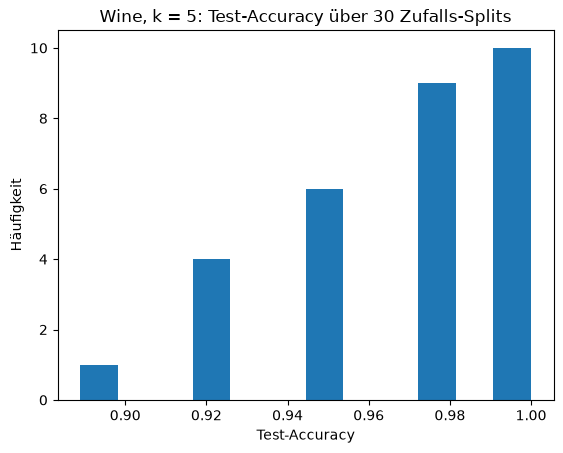

min = 0.889, max = 1.000, Spannweite = 0.111


In [14]:
split_accuracies = []
for seed in range(30):
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=seed)
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    model.fit(X_train, y_train)
    split_accuracies.append(accuracy_score(y_test, model.predict(X_test)))

plt.hist(split_accuracies, bins=12)
plt.title("Wine, k = 5: Test-Accuracy über 30 Zufalls-Splits")
plt.xlabel("Test-Accuracy")
plt.ylabel("Häufigkeit")
plt.show()

min_accuracy = float(min(split_accuracies))
max_accuracy = float(max(split_accuracies))
print(f"min = {min_accuracy:.3f}, max = {max_accuracy:.3f}, Spannweite = {max_accuracy - min_accuracy:.3f}")

In [15]:
cv_scores = cross_val_score(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)), X, y, cv=cv)
print(cv_scores.round(3))
print(f"Accuracy = {cv_scores.mean():.3f} ± {cv_scores.std():.3f} (5-fold CV)")

[0.972 0.972 1.    0.943 0.971]
Accuracy = 0.972 ± 0.018 (5-fold CV)


**Team A (97,4 %) vs. Team B (93,0 %):** Nein, man kann nicht sagen, dass A besser ist – dasselbe Modell schwankt allein durch die Wahl des Splits zwischen 0.889 und 1.000 (Spannweite ≈ 0.11), der Unterschied von 4,4 Prozentpunkten liegt also locker im reinen Zufallsrauschen eines einzelnen Splits mit nur 36 Testweinen.
Die CV-Angabe ist aussagekräftiger, weil jeder Datenpunkt genau einmal zur Validierung verwendet wird und über 5 Folds gemittelt wird, und weil die Standardabweichung (± 0.018) gleich mitliefert, wie stark das Ergebnis schwankt.

## B2: Erklärung für einen Mitschüler

**Erklärung an einen Mitschüler:**

> Stell dir vor, jemand sagt „Ich hab 94 % richtig!“ – dann weißt du noch nicht, ob er 10 oder 1000 Fragen hatte und ob die Fragen leicht oder schwer waren.
> Wenn zum Beispiel 94 von 100 Tierbildern Hunde sind, hat man schon mit „immer Hund raten“ 94 % richtig, ohne überhaupt etwas zu können.
> Und wurde nur ein einziges Mal getestet, kann es auch einfach Glück gewesen sein – deshalb muss man immer dazusagen, womit, wie oft und mit welcher Schwankung (± wie viel) getestet wurde.